In [36]:
from IPython.display import Image
import matplotlib.pyplot as plt
import scipy.stats
import numpy as np
import pandas as pd
import openmc
%matplotlib inline
import openmc.deplete
openmc.config['cross_sections']='/home/tasfia/openmc-setup-main/endfb-viii.0-hdf5/cross_sections.xml'
openmc.config['chain_file']='/home/tasfia/openmc-setup-main/endfb-viii.0-hdf5/chain_casl_sfr.xml'
import math

In [37]:
#material composition

#fuel composition
PuO2 = openmc.Material(material_id=1, name = 'Plutonium Dioxide')
PuO2.add_nuclide('Pu238', 0.01)
PuO2.add_nuclide('Pu239', 0.659)
PuO2.add_nuclide('Pu240', 0.252)
PuO2.add_nuclide('Pu241', 0.039)
PuO2.add_nuclide('Pu242', 0.04)
PuO2.add_nuclide('O16', 2.0)
PuO2.set_density('g/cm3', 10.887)

UO2_dep = openmc.Material(material_id=2, name = 'Depleted Uranium') # Depleted uranium dioxide
UO2_dep.add_element('U', 1, enrichment = 0.25)
UO2_dep.add_element('O', 2.0)
UO2_dep.set_density('g/cc', 11.08)
#UO2_dep.temperature = 1200

# Minor actinide (MA) composition

MA = openmc.Material(material_id=3,name = 'Minor Actinides')
MA.add_nuclide('Np237', 0.562, 'wo')
MA.add_nuclide('Am241', 0.264, 'wo')
MA.add_nuclide('Am243', 0.12, 'wo')
MA.add_nuclide('Cm243', 0.0003, 'wo')
MA.add_nuclide('Cm244', 0.0511, 'wo')
MA.add_nuclide('Cm245', 0.0026, 'wo')
MA.set_density('g/cm3', 15.43)

# --- computed mass fractions  ---
MOX1 = openmc.Material.mix_materials([UO2_dep, PuO2, MA],
    [0.772058487165646, 0.2097061918076057, 0.01823532102674831], 'wo')
MOX1.name = "MOX_inner (21.7 at% Pu+Am241)"
MOX1.id = 3

MOX2 = openmc.Material.mix_materials([UO2_dep, PuO2, MA],
    [0.7091255190889936, 0.267604522438126, 0.023269958472880506], 'wo')
MOX2.name = "MOX_outer (27.8 at% Pu+Am241)"
MOX2.id = 4

# Gas gap composition
helium = openmc.Material(material_id=5, name='Helium')
helium.set_density('g/cm3', 0.001598)
helium.add_element('He', 1,'wo')
helium.temperature = 1200

# Clad composition
t91 = openmc.Material(material_id=6, name='clad material')
t91.set_density('g/cm3', 7.7)
t91.add_element('Fe', 0.884, 'wo')
t91.add_element('Cr', 0.09, 'wo')
t91.add_element('Mo', 0.01  , 'wo')
t91.add_element('Mn', 0.006, 'wo')
t91.add_element('Si', 0.005, 'wo')
t91.add_element('V', 0.002, 'wo')
t91.add_element('Ni', 0.002, 'wo')
t91.add_element('Nb', 0.001, 'wo')
t91.temperature= 900
#t91.temperature = 900 # The maximum clad temperature at normal operating conditions is 550°C or 823 K.

# Coolant composition 
lead = openmc.Material(material_id=7, name='Lead Coolant')
lead.add_element('Pb', 1)
lead.set_density('g/cm3', 10.58)
lead.temperature = 600 # The core inlet temperature is 400°C.

# Absorber material
b4c = openmc.Material(material_id=8, name='Boron Carbide Absorber')
b4c.add_element('B', 4, enrichment = 90.0, enrichment_target = 'B10')
b4c.add_element('C', 1)
b4c.set_density('g/cm3', 2.52)
b4c.temperature = 600

#reflector material
reflector = openmc.Material(material_id=9, name='Zirconium Carbide')
reflector.set_density('g/cm3', 6.6)  # density at ~600 K
reflector.add_element('Zr', 1)      
reflector.add_element('C', 1)
reflector.temperature = 600

MOX1.temperature= 1200
MOX2.temperature= 1200

/usr/local/lib/python3.10/dist-packages/openmc/mixin.py:70: IDWarning: Another Material instance already exists with id=1.
  warn(msg, IDWarning)
/usr/local/lib/python3.10/dist-packages/openmc/mixin.py:70: IDWarning: Another Material instance already exists with id=2.
  warn(msg, IDWarning)
/usr/local/lib/python3.10/dist-packages/openmc/mixin.py:70: IDWarning: Another Material instance already exists with id=3.
  warn(msg, IDWarning)
/usr/local/lib/python3.10/dist-packages/openmc/mixin.py:70: IDWarning: Another Material instance already exists with id=4.
  warn(msg, IDWarning)
/usr/local/lib/python3.10/dist-packages/openmc/mixin.py:70: IDWarning: Another Material instance already exists with id=5.
  warn(msg, IDWarning)
/usr/local/lib/python3.10/dist-packages/openmc/mixin.py:70: IDWarning: Another Material instance already exists with id=6.
  warn(msg, IDWarning)
/usr/local/lib/python3.10/dist-packages/openmc/mixin.py:70: IDWarning: Another Material instance already exists with id=7.
 

In [38]:
# Instantiate a materials collection and export it to XML

materials_file = openmc.Materials([ MOX1, MOX2, helium, t91, lead, b4c, reflector])
materials_file.export_to_xml()
mat_colours= {t91:'black', helium:'skyblue', lead:'silver',
                      reflector:'magenta', MOX1:'blue', MOX2:'green', b4c:'cyan'}

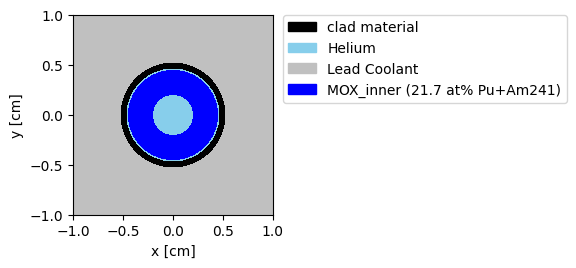

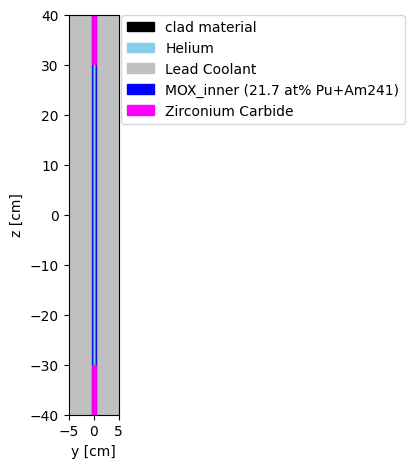

In [39]:
# fuel rod inner zone of the core

fuel_ir  = openmc.ZCylinder(r=0.20)
fuel_or  = openmc.ZCylinder(r=0.45)
clad_ir  = openmc.ZCylinder(r=0.465)
clad_or  = openmc.ZCylinder(r=0.525)

top_fuel      = openmc.ZPlane(z0=30, name='top')
bottom_fuel   = openmc.ZPlane(z0=-30, name='bottom')

top      = openmc.ZPlane(z0=40, name='top', boundary_type = 'reflective')
bottom   = openmc.ZPlane(z0=-40, name='bottom', boundary_type = 'reflective')


hole = openmc.Cell(name='Hole', region = -fuel_ir & -top_fuel & +bottom_fuel, fill = helium)
fuel_iz = openmc.Cell(name='Inner Zone Fuel', region  = +fuel_ir & -fuel_or & -top_fuel & +bottom_fuel, fill = MOX1) # iz refers to inner zone.
gap = openmc.Cell(name='Gap', region  = +fuel_or & -clad_ir & -top_fuel & +bottom_fuel, fill = helium)
clad = openmc.Cell(name='Cladding', region = +clad_ir & -clad_or& -top & +bottom, fill = t91)
bottom_reflector = openmc.Cell(name='Bottom Reflector', region = -clad_ir & +bottom & -bottom_fuel, fill = reflector)
top_reflector = openmc.Cell(name='Top Reflector', region = -clad_ir & +top_fuel & -top, fill = reflector)
coolant = openmc.Cell(name='Coolant', region = +clad_or, fill = lead)


f_iz = openmc.Universe(cells=[hole, fuel_iz, gap, clad, coolant, bottom_reflector, top_reflector])
f_iz.plot(width=(2.0,2.0), color_by = 'material', colors = {t91:'black', helium:'skyblue', lead:'silver',
                       MOX1:'blue'}, legend=True)
f_iz.plot(basis='yz', width=(10,80), pixels= (400,400), color_by = 'material', colors = {t91:'black', helium:'skyblue', lead:'silver',
                       MOX1:'blue', reflector:'magenta'}, legend=True)

# Instantiate coolant universe
lead_cell = openmc.Cell(fill=lead)
lead_univ = openmc.Universe(cells=[lead_cell])
 

Text(0.5, 1.0, 'Inner Zone Assembly — YZ View')

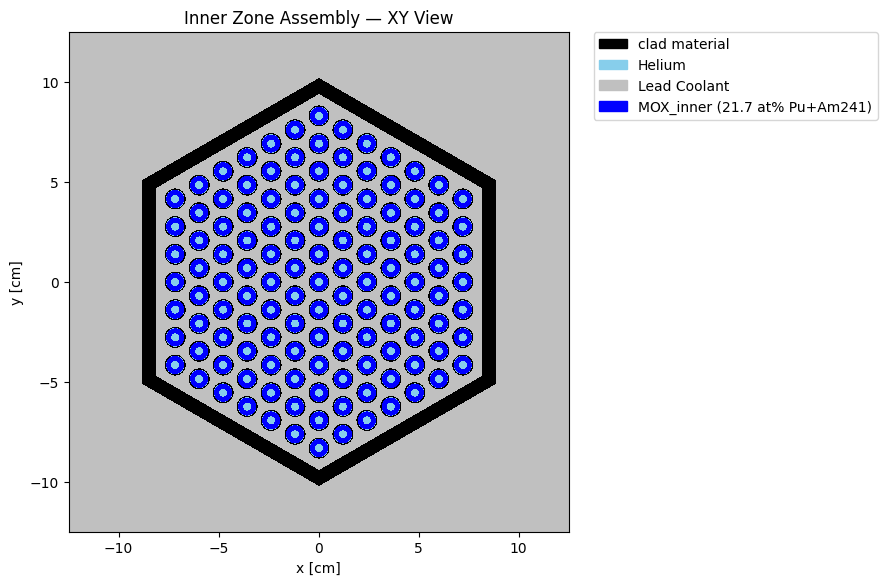

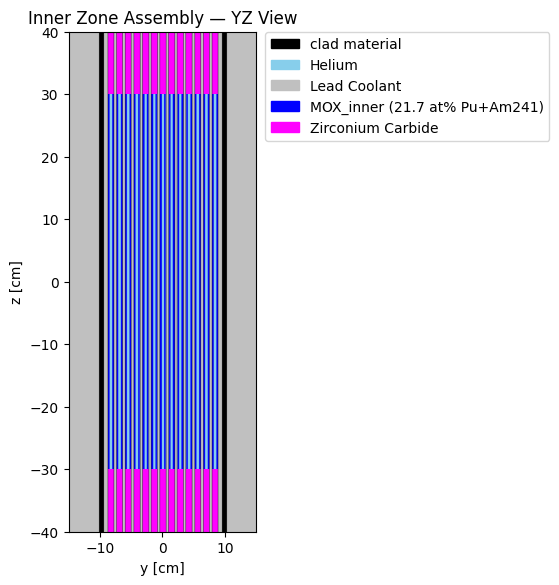

In [40]:
#Fuel assembly of inner zone

fa_iz = openmc.HexLattice()
fa_iz.center = (0., 0.)
fa_iz.pitch = (1.384,)
fa_iz.outer = lead_univ
fa_iz.orientation = 'y'

outer_ring = [f_iz]*36

ring_1 = [f_iz]*30

ring_2 = [f_iz]*24

ring_3 = [f_iz]*18

ring_4 = [f_iz]*12

ring_5 = [f_iz]*6

inner_ring = [f_iz]

fa_iz.universes = [outer_ring,  ring_1,  ring_2,  ring_3,  ring_4,  ring_5,  inner_ring]

# Create the prism that will contain the lattice
outer_in_surface = openmc.model.hexagonal_prism(edge_length=9.4, orientation='y')
wrapper_in_surface=openmc.model.hexagonal_prism(edge_length=10.2, orientation='y')
wrapper_cell=openmc.Cell(fill = t91, 
                    region= ~outer_in_surface & wrapper_in_surface & 
                    -top & +bottom)

# Fill a cell with the lattice. This cell is filled with the lattice and contained within the prism.
main_in_assembly = openmc.Cell(fill=fa_iz, region=outer_in_surface & -top & +bottom)

# Fill a cell with a material that will surround the lattice
out_in_assembly  = openmc.Cell(fill=lead, region=~wrapper_in_surface & -top & +bottom)

# Create a universe that contains both 
main_in_u = openmc.Universe(cells=[main_in_assembly, out_in_assembly,wrapper_cell])

# Plot the universe
main_in_u.plot(origin = (0,0,0), pixels=(500, 500), width = (25.,25.), color_by = 'material',
               colors = {t91:'black', helium:'skyblue', lead:'silver',
                       MOX1:'blue'}, legend=True)
plt.title("Inner Zone Assembly — XY View")
main_in_u.plot(basis='yz', origin = (0,0,0), pixels=(500, 500), width = (30.,80.), color_by = 'material',
               colors = {t91:'black', helium:'skyblue', lead:'silver',
                       MOX1:'blue', reflector:'magenta'}, legend=True)
plt.title("Inner Zone Assembly — YZ View")

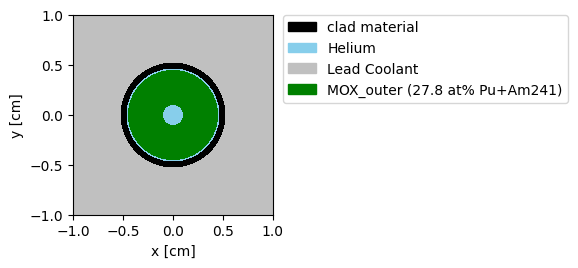

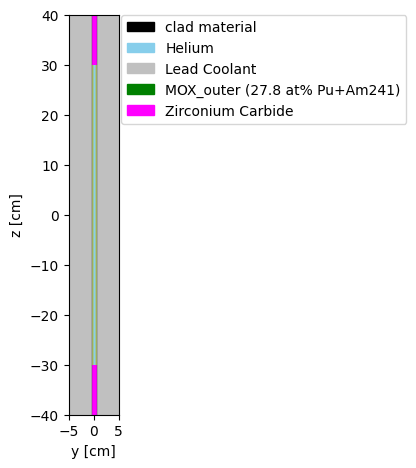

In [41]:
# Instantiate cylindrical surfaces (fuel of outer zone of the core)


fuel_ir  = openmc.ZCylinder(r=0.10)
fuel_or  = openmc.ZCylinder(r=0.45)
clad_ir  = openmc.ZCylinder(r=0.465)
clad_or  = openmc.ZCylinder(r=0.525)

top_fuel      = openmc.ZPlane(z0=30, name='top')
bottom_fuel   = openmc.ZPlane(z0=-30, name='bottom')

top      = openmc.ZPlane(z0=40, name='top', boundary_type = 'reflective')
bottom   = openmc.ZPlane(z0=-40, name='bottom', boundary_type = 'reflective')


hole = openmc.Cell(name='Hole', region = -fuel_ir & -top_fuel & +bottom_fuel, fill = helium)
fuel_oz = openmc.Cell(name='Inner Zone Fuel', region  = +fuel_ir & -fuel_or & -top_fuel & +bottom_fuel, fill = MOX2) # oz refers to outer zone.
gap = openmc.Cell(name='Gap', region  = +fuel_or & -clad_ir & -top_fuel & +bottom_fuel, fill = helium)
clad = openmc.Cell(name='Cladding', region = +clad_ir & -clad_or& -top & +bottom, fill = t91)
bottom_reflector = openmc.Cell(name='Bottom Reflector', region = -clad_ir & +bottom & -bottom_fuel, fill = reflector)
top_reflector = openmc.Cell(name='Top Reflector', region = -clad_ir & +top_fuel & -top, fill = reflector)
coolant = openmc.Cell(name='Coolant', region = +clad_or, fill = lead)


f_oz = openmc.Universe(cells=[hole, fuel_oz, gap, clad, coolant, bottom_reflector, top_reflector])
f_oz.plot(width=(2.0,2.0), color_by = 'material', colors = {t91:'black', helium:'skyblue', lead:'silver',
                       MOX2:'green'}, legend=True)
f_iz.plot(basis='yz', width=(10,80), pixels= (400,400), color_by = 'material', colors = {t91:'black', helium:'skyblue', lead:'silver',
                       MOX2:'green', reflector:'magenta'}, legend=True)


Text(0.5, 1.0, 'Outer Zone Assembly — YZ View')

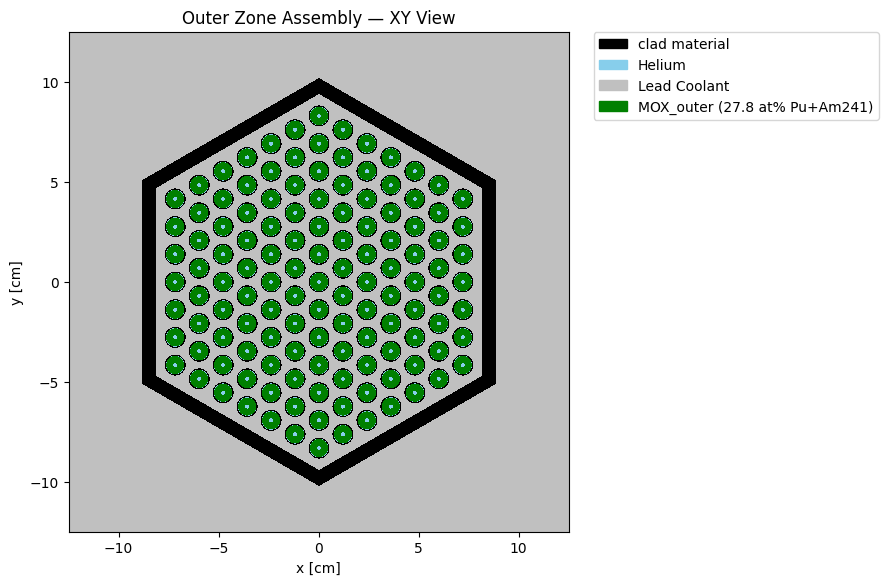

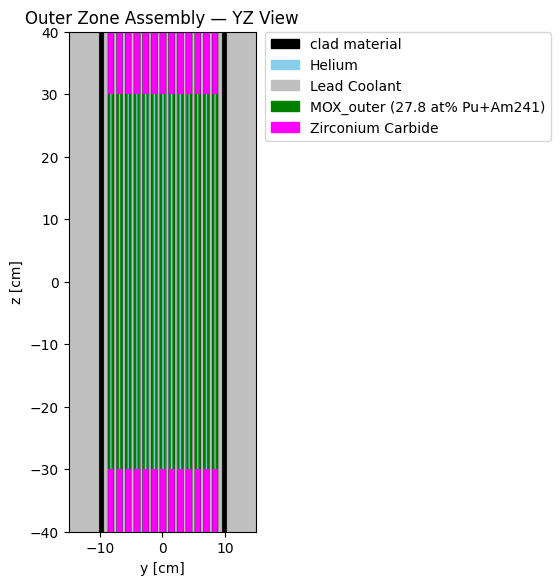

In [42]:
# Fuel assembly of the outer zone

fa_oz = openmc.HexLattice()
fa_oz.center = (0., 0.)
fa_oz.pitch = (1.384,)
fa_oz.outer = lead_univ
fa_oz.orientation = 'y'

outer_ring = [f_oz]*36

ring_1 = [f_oz]*30

ring_2 = [f_oz]*24

ring_3 = [f_oz]*18

ring_4 = [f_oz]*12

ring_5 = [f_oz]*6

inner_ring = [f_oz]

fa_oz.universes = [outer_ring, ring_1, ring_2, ring_3, ring_4, ring_5, inner_ring]

# Create the prism that will contain the lattice
outer_out_surface = openmc.model.hexagonal_prism(edge_length=9.4, orientation='y')
wrapper_out_surface=openmc.model.hexagonal_prism(edge_length=10.2, orientation='y')
wrapper_cell1=openmc.Cell(fill = t91, 
                    region= ~outer_out_surface & wrapper_out_surface & 
                    -top & +bottom)

# Fill a cell with the lattice. This cell is filled with the lattice and contained within the prism.
main_out_assembly = openmc.Cell(fill=fa_oz, region=outer_out_surface)

# Fill a cell with a material that will surround the lattice
out_out_assembly  = openmc.Cell(fill=lead, region=~wrapper_out_surface)

# Create a universe that contains both 
main_out_u = openmc.Universe(cells=[main_out_assembly, out_out_assembly, wrapper_cell1])

# Plot the universe
# Plot the universe
main_out_u.plot(origin = (0,0,0), pixels=(500, 500), width = (25.,25.), color_by = 'material',
               colors = {t91:'black', helium:'skyblue', lead:'silver',
                       MOX2:'green'}, legend=True)
plt.title("Outer Zone Assembly — XY View")
main_out_u.plot(basis='yz', origin = (0,0,0), pixels=(500, 500), width = (30.,80.), color_by = 'material',
               colors = {t91:'black', helium:'skyblue', lead:'silver',
                       MOX2:'green', reflector:'magenta'}, legend=True)
plt.title("Outer Zone Assembly — YZ View")


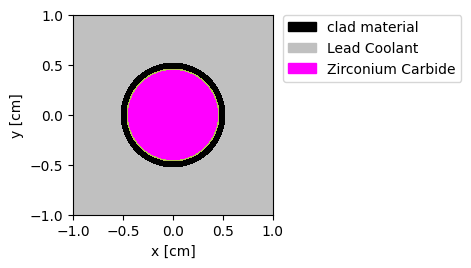

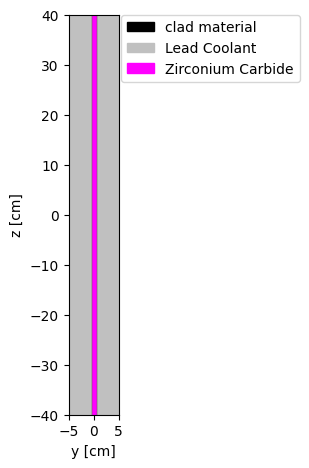

In [43]:
# Instantiate cylindrical surfaces (reflector zone)


fuel_or  = openmc.ZCylinder(r=0.45)
clad_ir  = openmc.ZCylinder(r=0.465)
clad_or  = openmc.ZCylinder(r=0.525)

top      = openmc.ZPlane(z0=40, name='top', boundary_type = 'reflective')
bottom   = openmc.ZPlane(z0=-40, name='bottom', boundary_type = 'reflective')


# Instantiate cells and fill with materials
ref = openmc.Cell(name='refletor cell', region  = -fuel_or & -top & +bottom, fill = reflector)
gap = openmc.Cell(name='Gap', region  = +fuel_or & -clad_ir& -top & +bottom, fill = helium)
clad = openmc.Cell(name='Cladding', region = +clad_ir & -clad_or& -top & +bottom, fill = t91)
coolant = openmc.Cell(name='Coolant', region = +clad_or, fill = lead)


# Instantiate reflector fuel universe
f_b = openmc.Universe(cells=[ref, gap, clad, coolant])
f_b.plot(width=(2.0,2.0), color_by = 'material',colors = {t91:'black', lead:'silver',
                        reflector:'magenta'}, legend=True)
f_b.plot(basis='yz', width=(10,80), pixels= (400,400), color_by = 'material', colors = {t91:'black', lead:'silver',
                       reflector:'magenta'}, legend=True)

Text(0.5, 1.0, 'Reflector Assembly — YZ View')

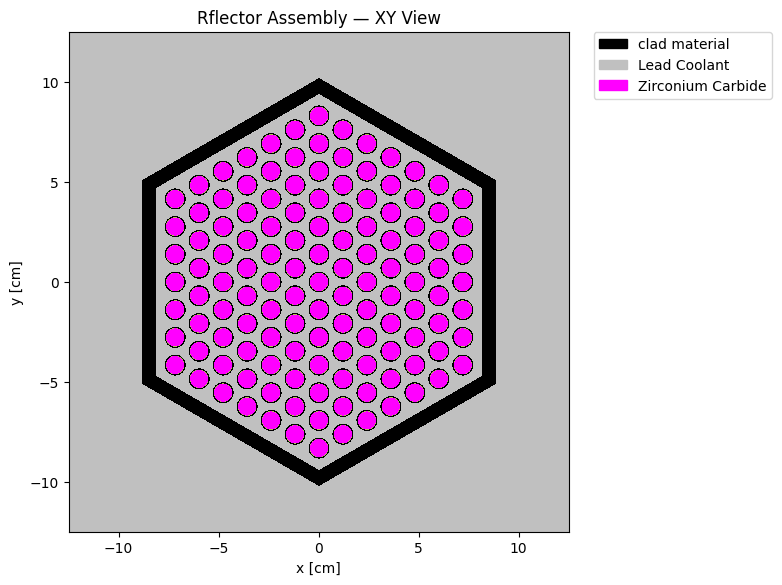

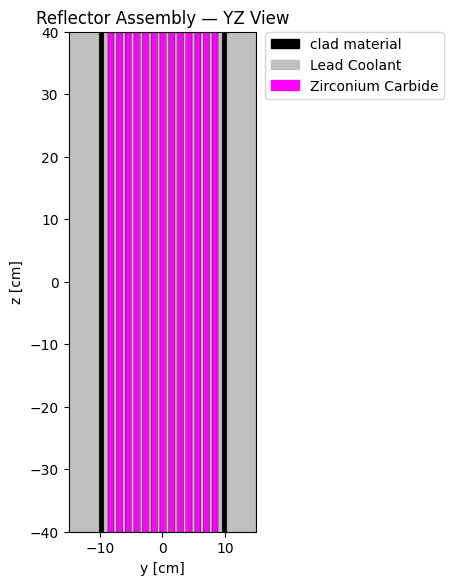

In [44]:
#reflector assembly 

ba = openmc.HexLattice()
ba.center = (0., 0.)
ba.pitch = (1.384,)
ba.outer = lead_univ
ba.orientation = 'y'

outer_ring = [f_b]*36

ring_1 = [f_b]*30

ring_2 = [f_b]*24

ring_3 = [f_b]*18

ring_4 = [f_b]*12

ring_5 = [f_b]*6

inner_ring = [f_b]

ba.universes = [outer_ring, ring_1, ring_2, ring_3, ring_4, ring_5, inner_ring]

# Create the prism that will contain the lattice
out_out_surface = openmc.model.hexagonal_prism(edge_length = 9.4, orientation='y')
wrapper_outer_surface=openmc.model.hexagonal_prism(edge_length= 10.2, orientation='y')
wrapper_cell2=openmc.Cell(fill = t91, 
                    region= ~out_out_surface & wrapper_outer_surface & 
                    -top & +bottom)

# Fill a cell with the lattice. This cell is filled with the lattice and contained within the prism.
main_out_assembly = openmc.Cell(fill=ba, region=out_out_surface)

# Fill a cell with a material that will surround the lattice
out_out_assembly  = openmc.Cell(fill=lead, region=~wrapper_outer_surface)

# Create a universe that contains both 
ba_u = openmc.Universe(cells=[main_out_assembly, out_out_assembly, wrapper_cell2])

# Plot the universe
ba_u.plot(origin = (0,0,0), pixels=(500, 500), width = (25.,25.), color_by = 'material',
               colors = {t91:'black', lead:'silver',
                        reflector:'magenta'}, legend=True)
plt.title("Rflector Assembly — XY View")
ba_u.plot(basis='yz', origin = (0,0,0), pixels=(500, 500), width = (30.,80.), color_by = 'material',
               colors = {t91:'black', lead:'silver',
                        reflector:'magenta'}, legend=True)
plt.title("Reflector Assembly — YZ View")

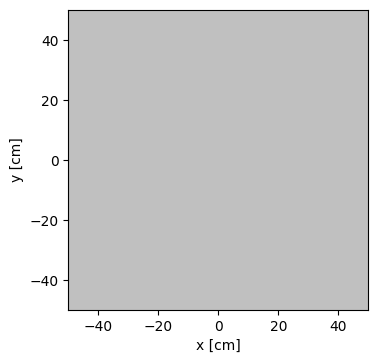

In [45]:
# Create a hexagonal lead assembly

lead_assembly = openmc.model.hexagonal_prism(edge_length=7*1.384, orientation='x')
la_cell = openmc.Cell(fill=lead, region=lead_assembly)
out_la_cell  = openmc.Cell(fill=lead, region=~lead_assembly)
lead_u = openmc.Universe(cells=[la_cell, out_la_cell])

lead_u.plot(origin = (0,0,0), pixels=(300, 300), width = (100.,100.), color_by = 'material',
            colors = mat_colours)

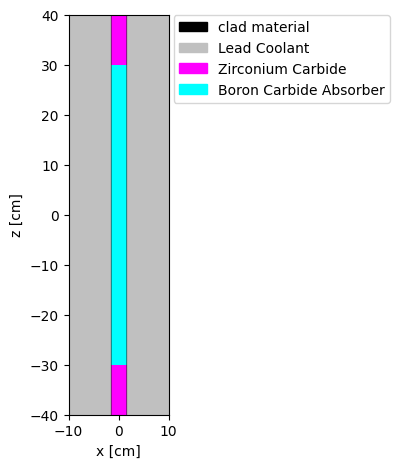

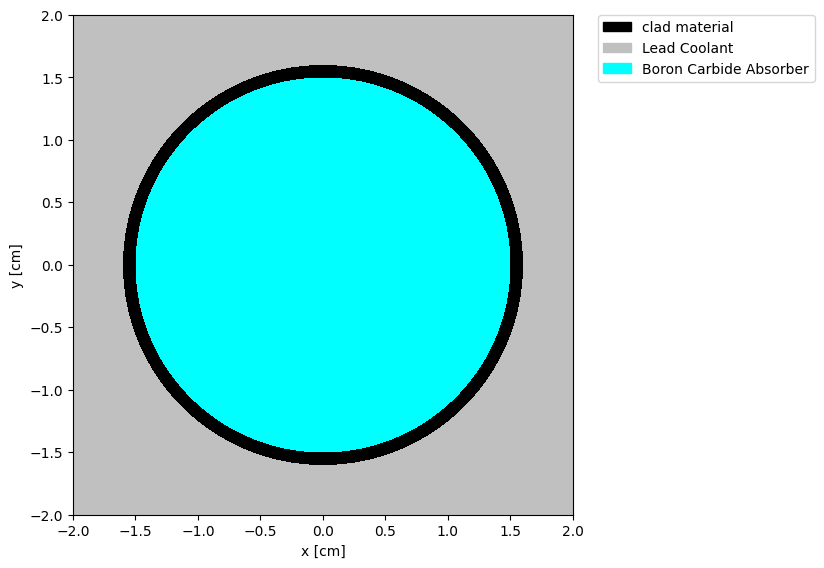

In [46]:
#control rod
control_rod_radius = openmc.ZCylinder(r=1.5)
control_rod_clad_radius = openmc.ZCylinder(r=1.6)
control_rod_bottom = openmc.ZPlane(z0 =-30)

control_rod_region = -control_rod_radius & -top_fuel & +control_rod_bottom 
control_rod_clad_region = -control_rod_clad_radius & +control_rod_radius & -top & +bottom 
control_rod_bottom_region = -control_rod_clad_radius & -control_rod_bottom & +bottom & +top_fuel

control_rod_coolant_region = +control_rod_clad_radius & -top & +bottom 

cr_cell = openmc.Cell(fill=b4c, region=control_rod_region)
cr_clad_cell = openmc.Cell(fill=t91, region=control_rod_clad_region)
cr_coolant_cell = openmc.Cell(fill=lead, region=control_rod_coolant_region)
cr_bottom_cell = openmc.Cell(fill=lead, region=control_rod_bottom_region)
bottom_reflector = openmc.Cell(name='Bottom Reflector', region = -control_rod_radius & +bottom & -control_rod_bottom, fill = reflector)
top_reflector = openmc.Cell(name='Top Reflector', region = -control_rod_radius & +top_fuel & -top, fill = reflector)

control_rod = openmc.Universe(cells=[cr_cell,cr_clad_cell,cr_coolant_cell,cr_bottom_cell, bottom_reflector, top_reflector])

control_rod.plot(origin = (0,0,0), pixels=(400, 400), width = (20,80), 
                 color_by = 'material', colors={t91:'black', lead:'silver',
                      reflector:'magenta', b4c:'cyan'}, basis='xz', legend=True)
control_rod.plot(origin = (0,0,0), pixels=(500, 500), width = (4,4), 
                 color_by = 'material',colors={t91:'black', lead:'silver',
                       b4c:'cyan'}, basis='xy', legend = True)

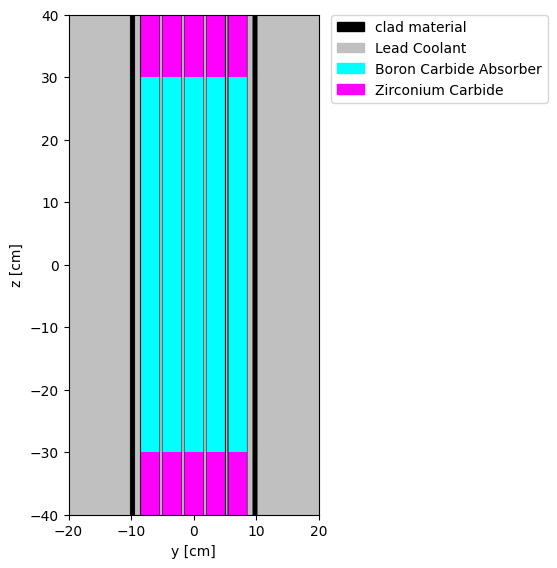

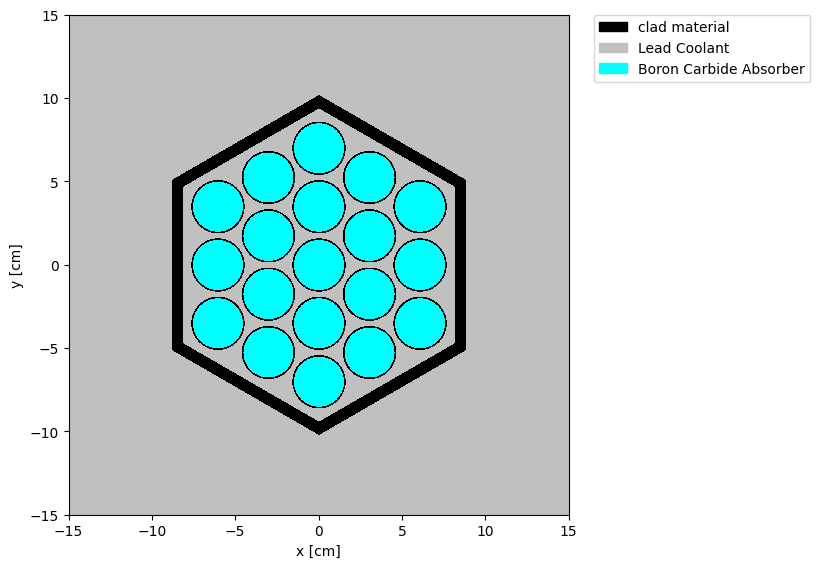

In [47]:
#control assembly
control_lat = openmc.HexLattice(name='control assembly')
control_lat.center = (0., 0.)
control_lat.pitch = (3.5,)
control_lat.orientation = 'y'
control_lat.outer = lead_univ

cring3= [control_rod]*12
cring2= [control_rod]*6
cring1= [control_rod]
control_lat.universes=[cring3,
                       cring2,
                       cring1]

control_lattice_boundary_in= openmc.model.hexagonal_prism(edge_length=9.4, orientation='y')
control_lattice_boundary_out= openmc.model.hexagonal_prism(edge_length=10.2, orientation='y')

control_wrapper_cell = openmc.Cell(fill=t91, 
                    region= ~control_lattice_boundary_in & control_lattice_boundary_out & 
                    -top & +bottom)
control_wrapper_cell_out = openmc.Cell(fill=lead, 
                    region= ~control_lattice_boundary_in & control_lattice_boundary_out & 
                    -bottom & +bottom)

control_cell = openmc.Cell(fill=control_lat, 
                    region= control_lattice_boundary_in & -top & +bottom)
control_surrounding = openmc.Cell(fill=lead, 
                    region= ~control_lattice_boundary_out & -top & +bottom)

control_u= openmc.Universe(cells=[control_cell,control_surrounding,
                                          control_wrapper_cell,control_wrapper_cell_out])

img1 = control_u.plot(origin = (0,0,0), pixels=(500, 500), width = (40,80), 
                          color_by = 'material', colors={t91:'black', lead:'silver',
                       b4c:'cyan',reflector:'magenta'}, basis='yz', legend=True)
img2 = control_u.plot(origin = (0,0,0), pixels=(500, 500), width = (30,30), 
                          color_by = 'material', colors={t91:'black', lead:'silver',
                       b4c:'cyan'}, basis='xy', legend=True)


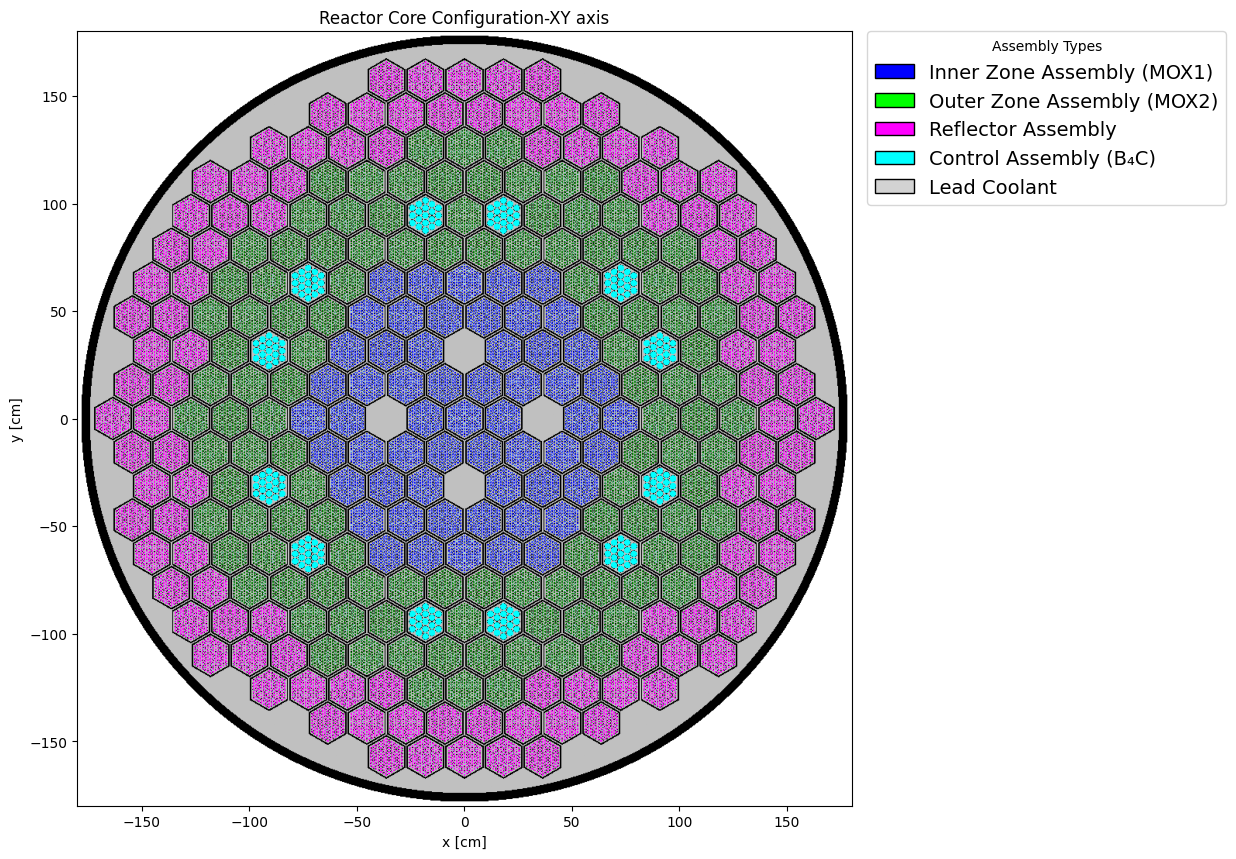

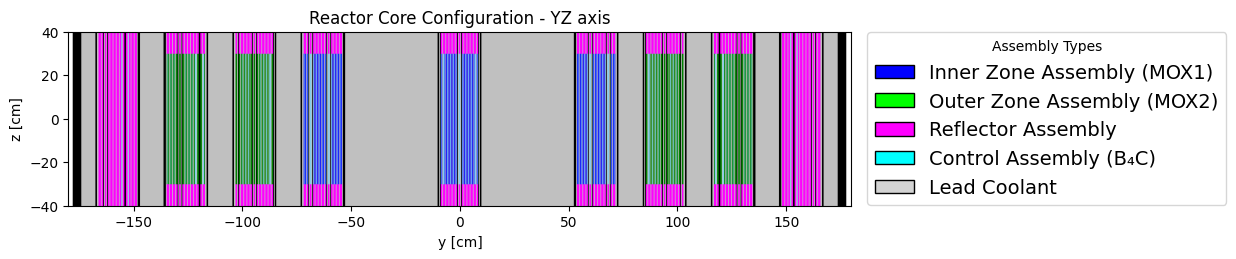

In [48]:
# Define the core lattice

core_lat = openmc.HexLattice(name='core')
core_lat.center = (0., 0.)
core_lat.pitch = (11*1.65,)
core_lat.outer = lead_univ
core_lat.orientation = 'x'

# Create rings of fuel universes that will fill the lattice

outer_ring = [lead_u, lead_u, lead_u, ba_u, ba_u, ba_u, ba_u, ba_u, lead_u, lead_u]*6

ring_9 = [ba_u]*9 + [lead_u] + [ba_u]*8 + [lead_u] + [ba_u]*17 + [lead_u] + [ba_u]*8 + [lead_u] + [ba_u]*8 

ring_8 = [ba_u, ba_u, ba_u, main_out_u, main_out_u, main_out_u, ba_u, ba_u]*6

ring_7 = [main_out_u, main_out_u, main_out_u, main_out_u, main_out_u, main_out_u, main_out_u]*6

ring_6 = [main_out_u, main_out_u, control_u, main_out_u, control_u, main_out_u]*6

ring_5 = [main_out_u, main_out_u, main_out_u, main_out_u, main_out_u]*6

ring_4 = [main_in_u]*24

ring_3 = [main_in_u]*18

ring_2 = [lead_u, main_in_u, main_in_u]*4

ring_1 = [main_in_u]*6

inner_ring = [main_in_u]

core_lat.universes = [outer_ring, ring_9, ring_8, ring_7, ring_6, ring_5, ring_4, ring_3, ring_2, ring_1, inner_ring]

# Create the prism that will contain the lattice
outer_core_surface = openmc.ZCylinder(r=174)
outer_vessel = openmc.ZCylinder(r=178, boundary_type='vacuum')

# Fill a cell with the lattice. This cell is filled with the lattice and contained within the prism.
core = openmc.Cell(fill=core_lat, region=-outer_core_surface & -top & +bottom)
vessel= openmc.Cell(fill=t91, region=-outer_vessel & +outer_core_surface & -top & +bottom)

# Create a universe that contains the lattice
main_u = openmc.Universe(cells=[core, vessel]) 

import matplotlib.patches as mpatches

img = main_u.plot(
    origin=(0, 0, 0),
    pixels=(1000, 1000),
    width=(360, 360),
    color_by='material',
    colors=mat_colours
)

# ---- Get current axis and figure ----
ax = plt.gca()
fig = plt.gcf()

# ---- Label and axis formatting ----
ax.set_xlim(-180, 180)
ax.set_ylim(-180, 180)
ax.set_xlabel('x [cm]')
ax.set_ylabel('y [cm]')
ax.set_title('Reactor Core Configuration-XY axis')

# ---- Define custom legend ----
legend_elements = [
    mpatches.Patch(facecolor='#0000FF', edgecolor='k', label='Inner Zone Assembly (MOX1)'),   # Blue
    mpatches.Patch(facecolor='#00FF00', edgecolor='k', label='Outer Zone Assembly (MOX2)'),   # Green
    mpatches.Patch(facecolor='#FF00FF', edgecolor='k', label='Reflector Assembly'), # Magenta
    mpatches.Patch(facecolor='#00FFFF', edgecolor='k', label='Control Assembly (B₄C)'),       # Cyan
    mpatches.Patch(facecolor='lightgray', edgecolor='k', label='Lead Coolant') # Gray
]

# ---- Add legend outside plot (right, top aligned) ----
ax.legend(
    handles=legend_elements,
    loc='upper left',
    bbox_to_anchor=(1.02, 1.0),
    borderaxespad=0.,
    fontsize=14,
    title='Assembly Types'
)

# ---- Adjust layout ----
plt.tight_layout(pad=2.5)
plt.show()

img = main_u.plot(basis='yz',origin=(0, 0, 0),pixels=(1000, 1000), width=(360, 80), color_by='material', colors=mat_colours)

# ---- Get current axis and figure ----
ax = plt.gca()
fig = plt.gcf()

ax.set_title('Reactor Core Configuration - YZ axis')

# ---- Define custom legend ----
legend_elements = [
    mpatches.Patch(facecolor='#0000FF', edgecolor='k', label='Inner Zone Assembly (MOX1)'),   # Blue
    mpatches.Patch(facecolor='#00FF00', edgecolor='k', label='Outer Zone Assembly (MOX2)'),   # Green
    mpatches.Patch(facecolor='#FF00FF', edgecolor='k', label='Reflector Assembly'), # Magenta
    mpatches.Patch(facecolor='#00FFFF', edgecolor='k', label='Control Assembly (B₄C)'),       # Cyan
    mpatches.Patch(facecolor='lightgray', edgecolor='k', label='Lead Coolant') # Gray
]

# ---- Add legend outside plot (right, top aligned) ----
ax.legend(
    handles=legend_elements,
    loc='upper left',
    bbox_to_anchor=(1.02, 1.0),
    borderaxespad=0.,
    fontsize=14,
    title='Assembly Types'
)

# ---- Adjust layout ----
plt.tight_layout(pad=2.5)
plt.show()

In [49]:
geometry = openmc.Geometry(main_u)
geometry.export_to_xml()

In [50]:
# OpenMC simulation parameters
batches = 100
inactive = 20
particles = 10000

In [51]:
# Instantiate a Settings object, set all runtime parameters, and export to XML
settings_file = openmc.Settings()
settings_file.temperature = {'method':'interpolation'}
settings_file.batches = batches
settings_file.inactive = inactive
settings_file.particles = particles
settings_file.energy_mode = 'continuous-energy'
#settings_file.create_delayed_neutrons = False

# Create an initial uniform spatial source distribution over fissionable zones
bounds = [-170, -170, -30, 170, 170, 30]
uniform_dist = openmc.stats.Box(bounds[:3], bounds[3:], only_fissionable=True)
settings_file.source = openmc.Source(space=uniform_dist)



settings_file.export_to_xml()

In [52]:
openmc.run()

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################